In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("02 brainstroke.csv")

In [3]:
df.head(5)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
# As for now just taking some of the columns for doing practise

df = pd.read_csv("02 brainstroke.csv", usecols = ['age', 'avg_glucose_level', 'bmi', 'stroke'])

In [5]:
df.head()

,age,avg_glucose_level,bmi,stroke
0,67.0,228.69,36.6,1
1,61.0,202.21,NaN,1
2,80.0,105.92,32.5,1
3,49.0,171.23,34.4,1
4,79.0,174.12,24.0,1


In [6]:
df.stroke.value_counts()

0    4861
1     249
Name: stroke, dtype: int64

# Let's first balance this class variable.

In [7]:
unique_values_stroke = df.stroke.unique()

unique_values_stroke

array([1, 0], dtype=int64)

In [8]:
balanced_class = []

In [9]:
for value in unique_values_stroke:
    subset = df[df.stroke == value]
    sampled_subset = subset.sample(n = min(250, len(subset)), replace = False)    
    
    # min(250, len(subset)) means select 250 or len(subset) whichever is minimun
    
    balanced_class.append(sampled_subset)

In [56]:
balanced_class[0]

,age,avg_glucose_level,bmi,stroke
128,82.0,200.59,29.0,1
209,63.0,106.58,23.9,1
13,78.0,219.84,NaN,1
123,56.0,249.31,35.8,1
155,77.0,231.56,36.9,1
...,...,...,...,...
178,80.0,110.66,NaN,1
53,77.0,124.13,31.4,1
217,55.0,210.40,40.0,1
228,39.0,97.76,29.6,1


In [57]:
balanced_class[1]

,age,avg_glucose_level,bmi,stroke
1732,63.0,217.66,28.7,0
4794,8.0,108.06,14.6,0
1850,78.0,84.49,26.4,0
4483,78.0,100.54,32.1,0
4527,4.0,94.27,14.0,0
...,...,...,...,...
2447,65.0,74.50,32.0,0
3915,61.0,68.17,43.8,0
3206,70.0,90.49,28.9,0
922,8.0,106.51,12.3,0


In [10]:
print(balanced_class[0].shape)
print(balanced_class[1].shape)

(249, 4)
(250, 4)


In [11]:
# Creating a new DataFrame with balanced class variable

new_df = pd.concat(balanced_class, ignore_index = True)

In [58]:
new_df.sample(10)

,age,avg_glucose_level,bmi,stroke
86,71.0,263.32,38.7,1
251,78.0,84.49,26.4,0
117,73.0,70.94,34.4,1
166,50.0,102.16,31.4,1
120,75.0,199.20,26.6,1
498,34.0,108.12,22.2,0
35,38.0,82.28,24.0,1
438,50.0,104.24,32.8,0
330,29.0,74.33,29.9,0
244,80.0,110.66,NaN,1


In [12]:
new_df.stroke.value_counts()

0    250
1    249
Name: stroke, dtype: int64

In [13]:
x = new_df.drop(columns = 'stroke', axis = 'columns')
y = new_df.drop(x, axis = 'columns')

In [14]:
print(x.head())

print()
print()
print()

print(y.head())

    age  avg_glucose_level   bmi
0  82.0             200.59  29.0
1  63.0             106.58  23.9
2  78.0             219.84   NaN
3  56.0             249.31  35.8
4  77.0             231.56  36.9



   stroke
0       1
1       1
2       1
3       1
4       1


In [15]:
x.isnull().sum()

age                   0
avg_glucose_level     0
bmi                  50
dtype: int64

# Filling missing values on 'bmi' column.

In [16]:
from sklearn.impute import KNNImputer

knnI = KNNImputer(n_neighbors = 5)

In [17]:
x['bmi'] = knnI.fit_transform(x[['bmi']])

In [18]:
x.isnull().sum()

age                  0
avg_glucose_level    0
bmi                  0
dtype: int64

# Train/ Test split.

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3)

# Graphical representation of distribution of values before Function Transformer.

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

C:\Users\jugal\AppData\Local\Temp\ipykernel_10880\312954863.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['age'])
C:\Users\jugal\AppData\Local\Temp\ipykernel_10880\312954863.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['avg_glucose_level'])
C:\Users\jugal\AppData\Loc

Text(0.5, 1.0, "PDF of 'bmi' before FunctionTransformer")

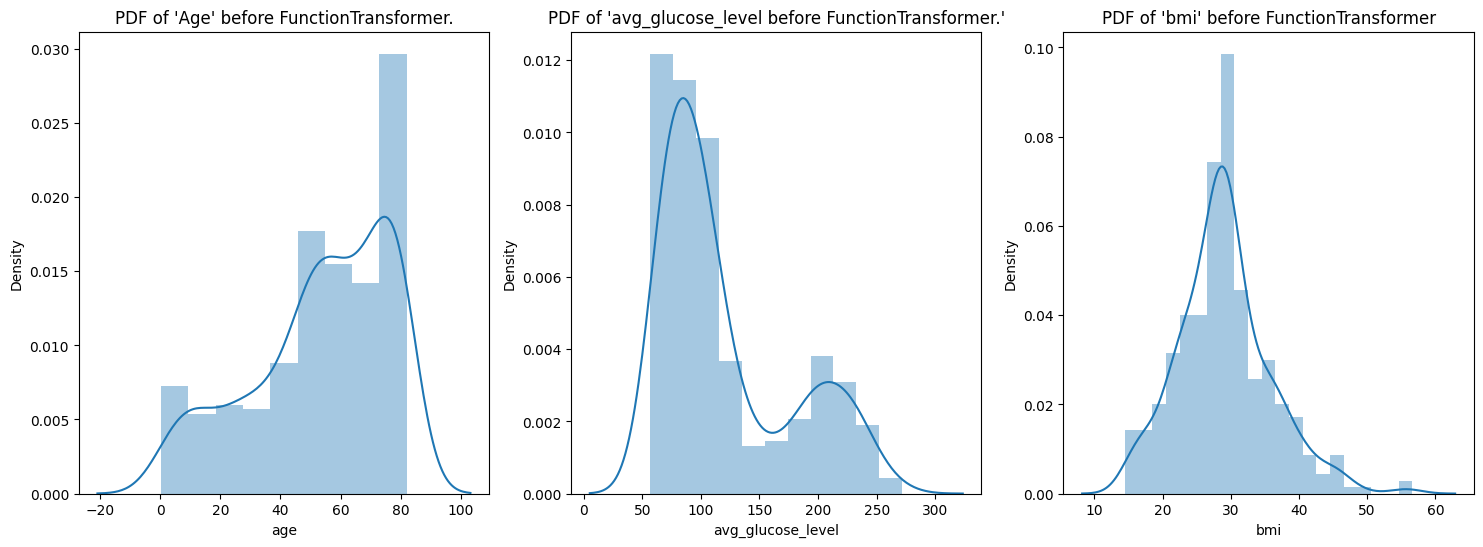

In [22]:
plt.figure(figsize = (18, 6))

plt.subplot(131)
sns.distplot(x_train['age'])
plt.title("PDF of 'Age' before FunctionTransformer.")

plt.subplot(132)
sns.distplot(x_train['avg_glucose_level'])
plt.title("PDF of 'avg_glucose_level before FunctionTransformer.'")

plt.subplot(133)
sns.distplot(x_train['bmi'])
plt.title("PDF of 'bmi' before FunctionTransformer")



Text(0.5, 1.0, "QQ plot of 'bmi' before FunctionTransformer")

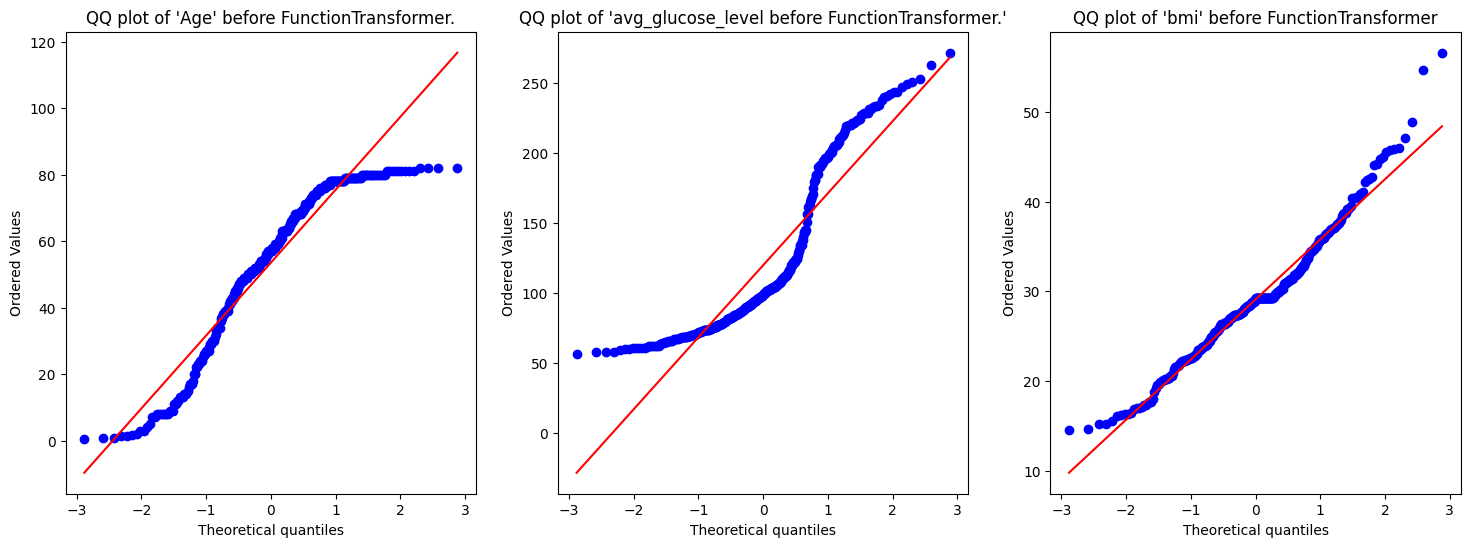

In [23]:
plt.figure(figsize = (18, 6))

plt.subplot(131)
stats.probplot(x_train['age'], dist = 'norm', plot = plt)
plt.title("QQ plot of 'Age' before FunctionTransformer.")

plt.subplot(132)
stats.probplot(x_train['avg_glucose_level'], dist = 'norm', plot = plt)
plt.title("QQ plot of 'avg_glucose_level before FunctionTransformer.'")

plt.subplot(133)
stats.probplot(x_train['bmi'], dist = 'norm', plot = plt)
plt.title("QQ plot of 'bmi' before FunctionTransformer")

# Applying FunctionTransformer.

In [24]:
from sklearn.preprocessing import FunctionTransformer

ft = FunctionTransformer(func = np.log1p)

In [25]:
x_train_transformed = ft.fit_transform(x_train)
x_test_transformed = ft.transform(x_test)

# Graphical representation of distribution of values after FunctionTransformer.

C:\Users\jugal\AppData\Local\Temp\ipykernel_10880\780291590.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train_transformed['age'])
C:\Users\jugal\AppData\Local\Temp\ipykernel_10880\780291590.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train_transformed['avg_glucose_level'])
C:

Text(0.5, 1.0, "PDF of 'bmi' after FunctionTransformer")

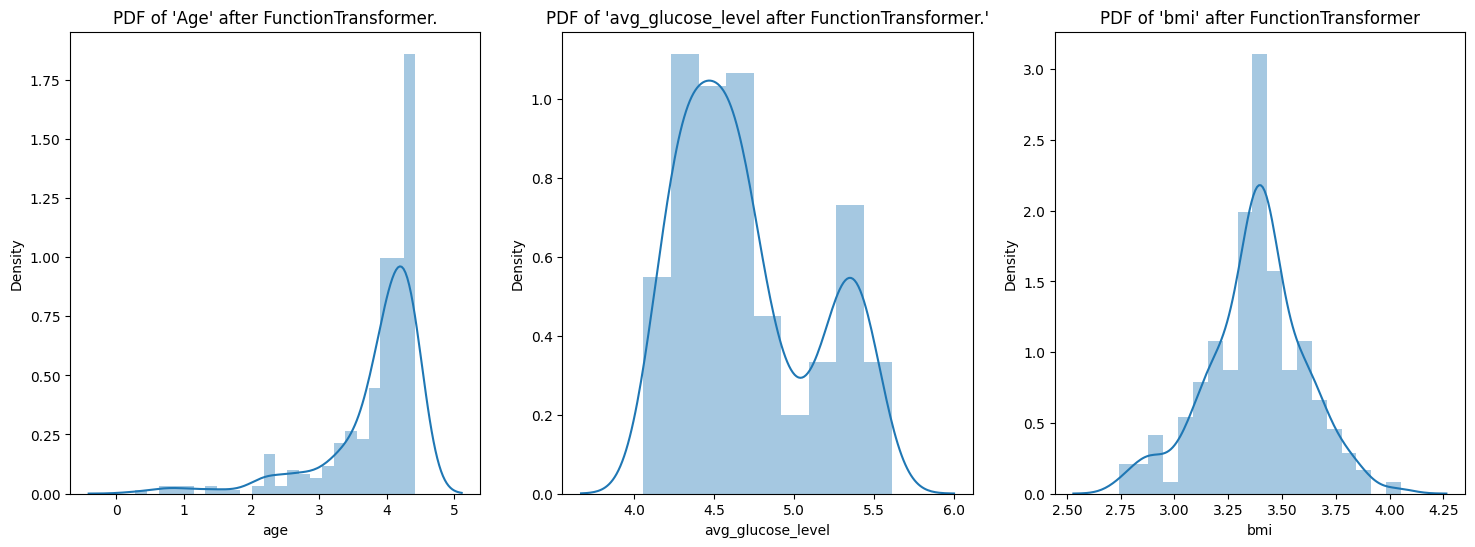

In [26]:
plt.figure(figsize = (18, 6))

plt.subplot(131)
sns.distplot(x_train_transformed['age'])
plt.title("PDF of 'Age' after FunctionTransformer.")

plt.subplot(132)
sns.distplot(x_train_transformed['avg_glucose_level'])
plt.title("PDF of 'avg_glucose_level after FunctionTransformer.'")

plt.subplot(133)
sns.distplot(x_train_transformed['bmi'])
plt.title("PDF of 'bmi' after FunctionTransformer")



Text(0.5, 1.0, "QQ plot of 'bmi' after FunctionTransformer")

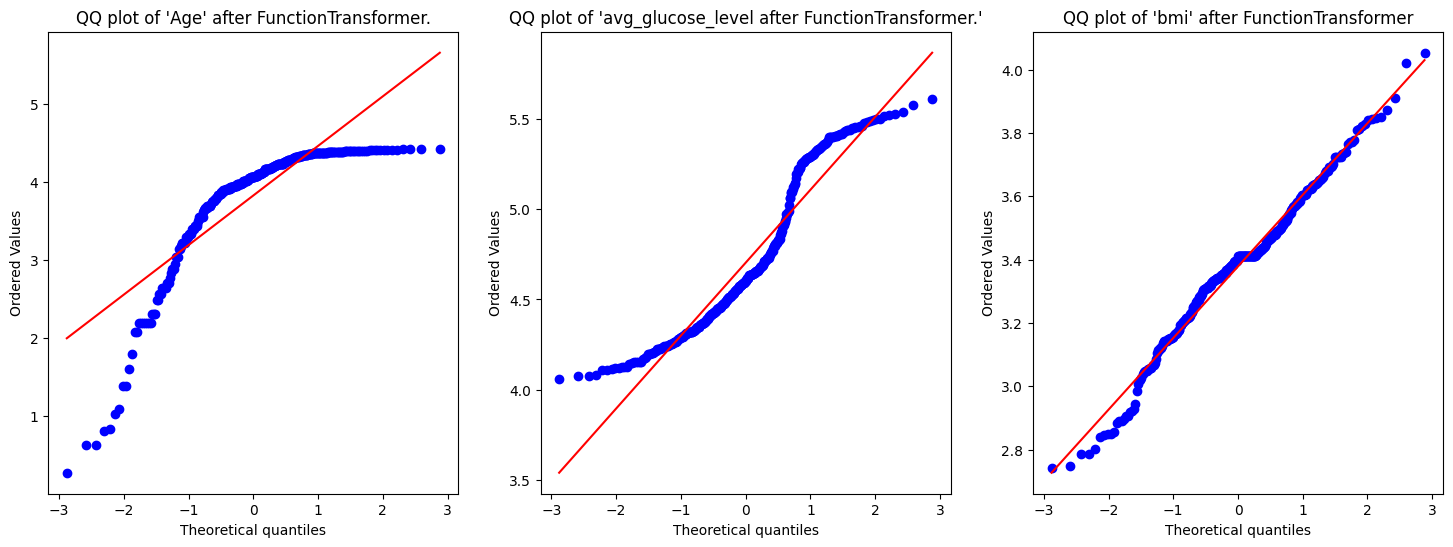

In [27]:
plt.figure(figsize = (18, 6))

plt.subplot(131)
stats.probplot(x_train_transformed['age'], dist = 'norm', plot = plt)
plt.title("QQ plot of 'Age' after FunctionTransformer.")

plt.subplot(132)
stats.probplot(x_train_transformed['avg_glucose_level'], dist = 'norm', plot = plt)
plt.title("QQ plot of 'avg_glucose_level after FunctionTransformer.'")

plt.subplot(133)
stats.probplot(x_train_transformed['bmi'], dist = 'norm', plot = plt)
plt.title("QQ plot of 'bmi' after FunctionTransformer")

In [28]:
# Comparing each column

C:\Users\jugal\AppData\Local\Temp\ipykernel_10880\2178937983.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['age'])
C:\Users\jugal\AppData\Local\Temp\ipykernel_10880\2178937983.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train_transformed['age'])


Text(0.5, 1.0, "PDF of 'age' after FunctionTransformer.'")

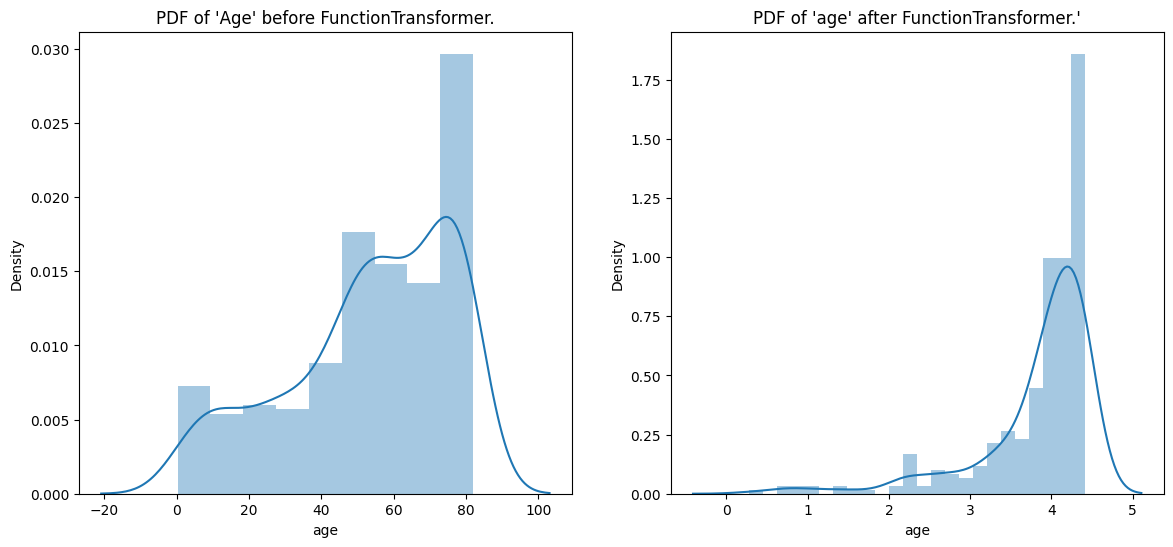

In [29]:
plt.figure(figsize = (14, 6))

plt.subplot(121)
sns.distplot(x_train['age'])
plt.title("PDF of 'Age' before FunctionTransformer.")

plt.subplot(122)
sns.distplot(x_train_transformed['age'])
plt.title("PDF of 'age' after FunctionTransformer.'")




C:\Users\jugal\AppData\Local\Temp\ipykernel_10880\1501927049.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['avg_glucose_level'])
C:\Users\jugal\AppData\Local\Temp\ipykernel_10880\1501927049.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train_transformed['avg_glucose_level']

Text(0.5, 1.0, "PDF of 'avg_glucose_level after FunctionTransformer.'")

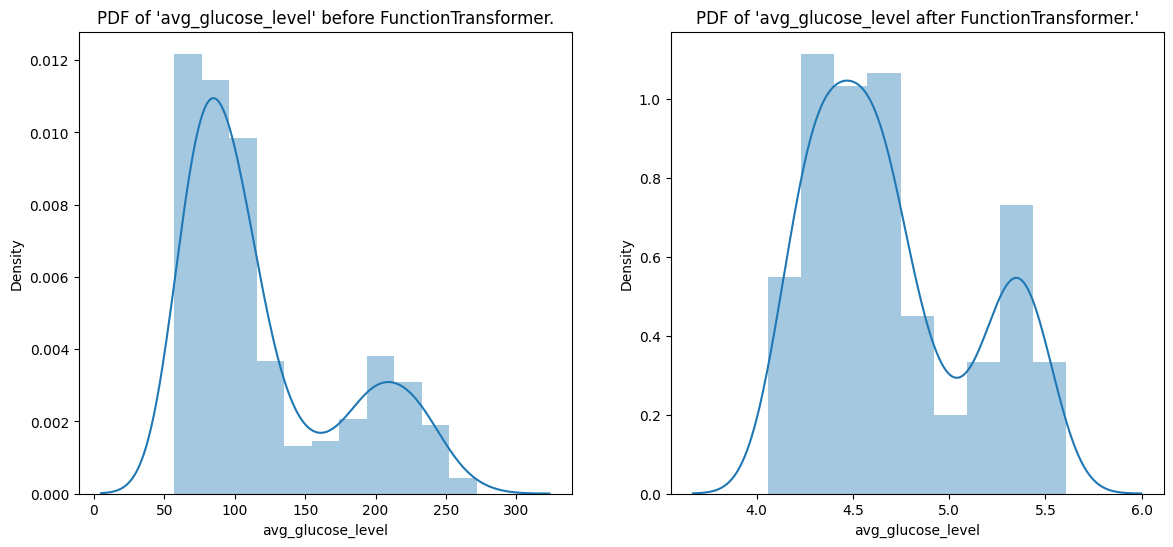

In [30]:
plt.figure(figsize = (14, 6))

plt.subplot(121)
sns.distplot(x_train['avg_glucose_level'])
plt.title("PDF of 'avg_glucose_level' before FunctionTransformer.")

plt.subplot(122)
sns.distplot(x_train_transformed['avg_glucose_level'])
plt.title("PDF of 'avg_glucose_level after FunctionTransformer.'")




C:\Users\jugal\AppData\Local\Temp\ipykernel_10880\4159592059.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['bmi'])
C:\Users\jugal\AppData\Local\Temp\ipykernel_10880\4159592059.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train_transformed['bmi'])


Text(0.5, 1.0, "PDF of 'bmi' after FunctionTransformer.")

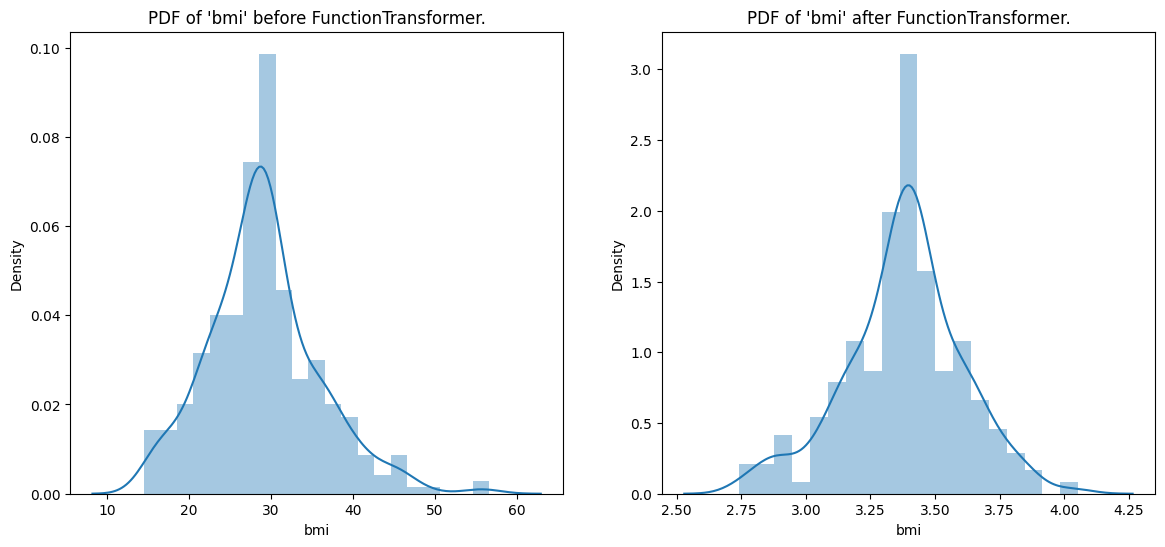

In [31]:
plt.figure(figsize = (14, 6))

plt.subplot(121)
sns.distplot(x_train['bmi'])
plt.title("PDF of 'bmi' before FunctionTransformer.")

plt.subplot(122)
sns.distplot(x_train_transformed['bmi'])
plt.title("PDF of 'bmi' after FunctionTransformer.")

# Comparison of QQ plots

Text(0.5, 1.0, "QQ plot of ''age' after FunctionTransformer.")

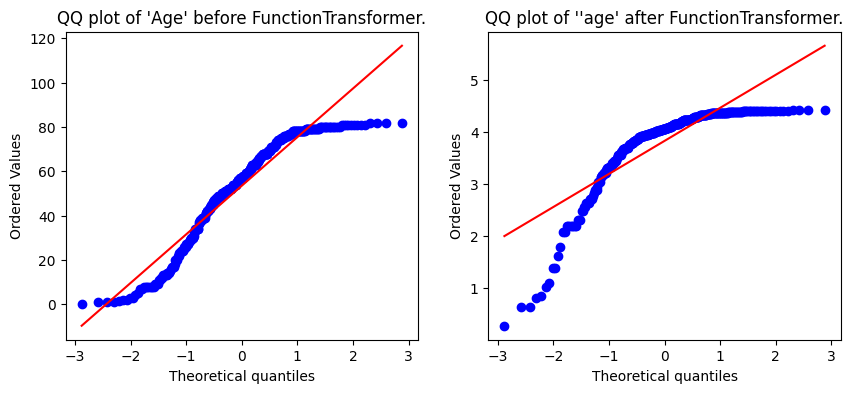

In [32]:
plt.figure(figsize = (10, 4))

plt.subplot(121)
stats.probplot(x_train['age'], dist = 'norm', plot = plt)
plt.title("QQ plot of 'Age' before FunctionTransformer.")

plt.subplot(122)
stats.probplot(x_train_transformed['age'], dist = 'norm', plot = plt)
plt.title("QQ plot of ''age' after FunctionTransformer.")

Text(0.5, 1.0, "QQ plot of 'avg_glucose_level' after FunctionTransformer.")

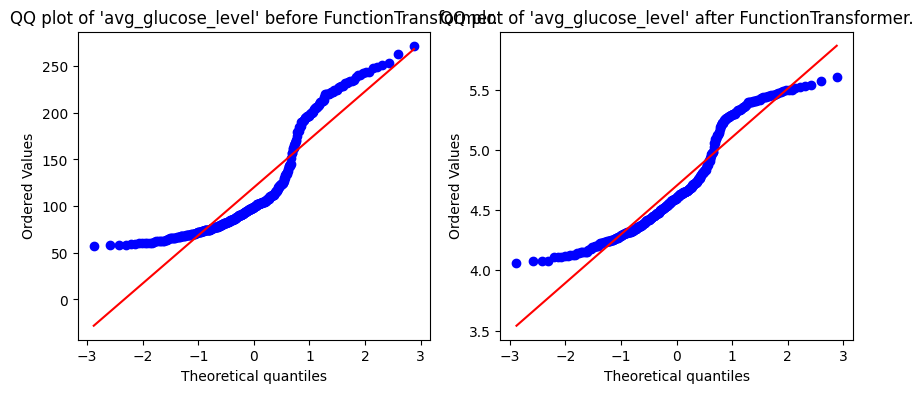

In [33]:
plt.figure(figsize = (10, 4))

plt.subplot(121)
stats.probplot(x_train['avg_glucose_level'], dist = 'norm', plot = plt)
plt.title("QQ plot of 'avg_glucose_level' before FunctionTransformer.")

plt.subplot(122)
stats.probplot(x_train_transformed['avg_glucose_level'], dist = 'norm', plot = plt)
plt.title("QQ plot of 'avg_glucose_level' after FunctionTransformer.")

Text(0.5, 1.0, "QQ plot of 'bmi' after FunctionTransformer.")

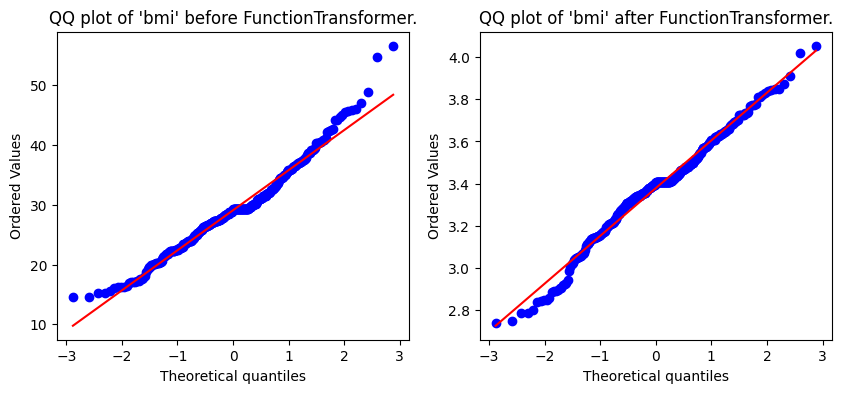

In [34]:
plt.figure(figsize = (10, 4))

plt.subplot(121)
stats.probplot(x_train['bmi'], dist = 'norm', plot = plt)
plt.title("QQ plot of 'bmi' before FunctionTransformer.")

plt.subplot(122)
stats.probplot(x_train_transformed['bmi'], dist = 'norm', plot = plt)
plt.title("QQ plot of 'bmi' after FunctionTransformer.")

# Model building and accuracy before and after FunctionTransformer,
1) Decision Tree
2) SVM
3) KNN

# 1) Decision Tree Classifier

In [35]:
from sklearn.tree import DecisionTreeClassifier


In [36]:
dt_x_train = DecisionTreeClassifier()
dt_x_train_trans = DecisionTreeClassifier()

In [37]:
# Fitting x_train on DecisionTree
dt_x_train.fit(x_train, y_train)    # Data before FT
dt_x_train_trans.fit(x_train_transformed, y_train)    # Data after FT

DecisionTreeClassifier()

In [38]:
# Prediction x_train on Decision Tree.

pred_x_test = dt_x_train.predict(x_test)    # Before FT
pred_x_test_transformed = dt_x_train_trans.predict(x_test_transformed)    # After FT

In [39]:
# Finding accuracy

from sklearn.metrics import accuracy_score

acc_x_test = accuracy_score(pred_x_test, y_test)    # Accuracy before FT
acc_x_test_transformed = accuracy_score(pred_x_test_transformed, y_test)    # Accuracy after FT.

print(f"Accuracy before FunctionTransformation: {acc_x_test}.")
print(f"Accuracy after FunctionTransformation: {acc_x_test_transformed}.")

Accuracy before FunctionTransformation: 0.6733333333333333.
Accuracy after FunctionTransformation: 0.6933333333333334.


# 2) Standard Vector Machine.

In [40]:
from sklearn.svm import SVC

In [41]:
svc_x_train = SVC()
svc_x_train_transformed = SVC()

In [42]:
svc_x_train.fit(x_train, y_train)
svc_x_train_transformed.fit(x_train_transformed, y_train)

C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVC()

In [43]:
# Making prediction on x_test and x_test_transformed.

pred_svc1 = svc_x_train.predict(x_test)
pred_svc2 = svc_x_train_transformed.predict(x_test_transformed)

In [44]:
# Getting accuracy score.

acc_svc1 = accuracy_score(pred_svc1, y_test)
acc_svc2 = accuracy_score(pred_svc2, y_test)

print(f"Accuracy on SVM before FT: {acc_svc1}.")
print(f"Accuracy on SVM after FT: {acc_svc2}.")

Accuracy on SVM before FT: 0.7733333333333333.
Accuracy on SVM after FT: 0.8133333333333334.


# 3) KNeighborClassifier.

In [45]:
from sklearn.neighbors import KNeighborsClassifier

In [46]:
knn_x_train = KNeighborsClassifier(n_neighbors = 10)
knn_x_train_transformed = KNeighborsClassifier(n_neighbors = 10)

In [47]:
# Fitting the model.

knn_x_train.fit(x_train, y_train)
knn_x_train_transformed.fit(x_train_transformed, y_train)

C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


KNeighborsClassifier(n_neighbors=10)

In [48]:
# MAking prediction

pred_knn1 = knn_x_train.predict(x_test)
pred_knn2 = knn_x_train_transformed.predict(x_test)

In [49]:
# Getting accuracy.

acc_knn1 = accuracy_score(pred_knn1, y_test)
acc_knn2 = accuracy_score(pred_knn2, y_test)

print(f"Accuracy on KNN before FT: {acc_knn1}.")
print(f"Accuracy on KNN after FT: {acc_knn2}.")

Accuracy on KNN before FT: 0.78.
Accuracy on KNN after FT: 0.5133333333333333.


# 4) LogisticRegression

In [50]:
from sklearn.linear_model import LogisticRegression

In [51]:
lr1 = LogisticRegression()
lr2 = LogisticRegression()

In [52]:
lr1.fit(x_train, y_train)
lr2.fit(x_train_transformed, y_train)

C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression()

In [53]:
pred_1 = lr1.predict(x_test)
pred_2 = lr2.predict(x_test_transformed)

In [54]:
acc_1 = accuracy_score(pred_1, y_test)
acc_2 = accuracy_score(pred_2, y_test)

print(f"Accuracy on LogisticRegerssion before FT: {acc_1}.")
print(f"Accuracy on LogisticRegerssion after FT: {acc_2}.")

Accuracy on LogisticRegerssion before FT: 0.8.
Accuracy on LogisticRegerssion after FT: 0.84.


# `Next Session`: Day - 31 Continuation of FunctionTransformer.